# Drosophila segment polarity patterning

This notebook reproduces the analysis of the Drosophila patterning model of the
[MaBoSS website](https://maboss.curie.fr).

The model of the segment polarity genes is based on a published model
([Albert and Othmer, 2003](https://doi.org/10.1016/s0022-5193(03)00035-3)), and the analysis on another
publication ([Chaves and Albert, 2008](https://doi.org/10.1098/rsif.2008.0132.focus)), which studied the
effect of random noise on this network.

The model consists of four identical signaling pathways, one for each of four adjacent cells, connected to
each other (cell 1 is adjacent to cell 4). mRNA (lower case, e.g. `en1`) and proteins (upper case, e.g. `EN1`)
are considered separately. Two transition rates are used: `$rate_RNA = 1` for transcriptional influences, and
`$rate_protein = 10` for post-transcriptional influences. Random noise on every node is tuned by the parameter
`$noise`.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `D_Pattern_ContT.bnd`,
`D_Pattern_ContT_noIntNode.cfg`, `D_Pattern_ContT_noIntNode_noise.cfg` and
`D_Pattern_ContT_noIntNode_noise_4statdist.cfg`, in the same folder as this notebook.

In [1]:
import math
import os
import maboss
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.offsetbox import HPacker

# The figures are saved in the "figures" folder
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"savefig.dpi": 150, "savefig.bbox": "tight", "figure.constrained_layout.use": True})

def legend_below():
    """Move the legend of the current figure below the plot, in centered rows of similar widths."""
    figure, legend = plt.gcf(), plt.gca().get_legend()
    handles, labels = legend.legend_handles, [text.get_text() for text in legend.get_texts()]
    legend.remove()
    legend = figure.legend(handles, labels, loc="outside lower center", ncols=1)
    # Matplotlib fills the rows from the left: we rearrange the entries of the legend in centered rows,
    # as few as possible within the width of the plot, and of similar widths
    column = legend._legend_handle_box.get_children()[0]
    entries, column.align = column.get_children(), "center"
    sep = legend.columnspacing * legend.prop.get_size_in_points() * figure.dpi / 72
    widths = [entry.get_bbox(figure.canvas.get_renderer()).width + sep for entry in entries]
    max_width = 0.8 * figure.get_figwidth() * figure.dpi
    for n_rows in range(math.ceil(sum(widths) / max_width), len(entries) + 1):
        rows, row_widths = [[]], [0]
        for entry, width in zip(entries, widths):
            if rows[-1] and row_widths[-1] + width / 2 > sum(widths) / n_rows:
                rows.append([])
                row_widths.append(0)
            rows[-1].append(entry)
            row_widths[-1] += width
        if max(row_widths) <= max_width:
            break
    column._children = [HPacker(sep=sep, align="baseline", children=row) for row in rows]

## Patterns

A state of the network is a pattern: the activity of each gene in each of the four cells. As there is no
built-in plot for this, we define a small function to draw a pattern from a list of active nodes.

In [2]:
GENES = ["wg", "WG", "en", "EN", "hh", "HH", "ptc", "PTC", "ci", "CI", "CIA", "CIR", "SLP"]

def plot_pattern(active, title):
    pattern = pd.DataFrame({cell: [int(f"{gene}{cell}" in active) for gene in GENES] for cell in [1, 2, 3, 4]},
                           index=GENES)
    plt.figure(figsize=(2, 4))
    plt.imshow(pattern, cmap="Greys", aspect="auto")
    plt.xticks(range(4), pattern.columns)
    plt.yticks(range(len(GENES)), GENES)
    plt.xlabel("cell")
    plt.title(title)

The model should produce the expected patterning (the reference state, in which none of the four cells are
identical) starting from the initial state below, when the pair rule gene SLP has the pattern SLP1,2 = 0 and
SLP3,4 = 1. The reference state is used to compute the Hamming distance distribution: the probability that a
state differs from the reference state on a given number of nodes.

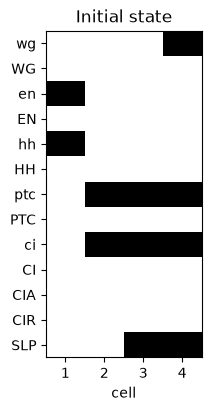

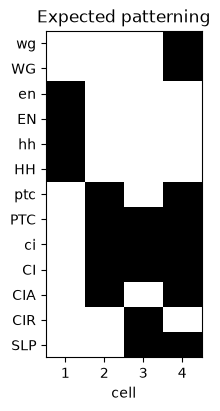

In [3]:
no_noise = maboss.load("D_Pattern_ContT.bnd", "D_Pattern_ContT_noIntNode.cfg")

initial = [node for node, value in no_noise.get_initial_state().items() if value == 1]
reference = [node for node, value in no_noise.refstate.items() if value] + ["SLP3", "SLP4"]

plot_pattern(initial, "Initial state")
plt.savefig("figures/droso_initial.png")
plot_pattern(reference, "Expected patterning")
plt.savefig("figures/droso_reference.png")

## Without noise

When there is no noise (`$noise = 0`), the expected patterning is reached. This can be seen on the trajectories
of the Hamming distance distribution (HD), with the expected patterning as the reference state. pyMaBoSS does
not have a function to plot them: we read them from the trajectory file of the results, and plot the values
having a final probability of at least 2%.

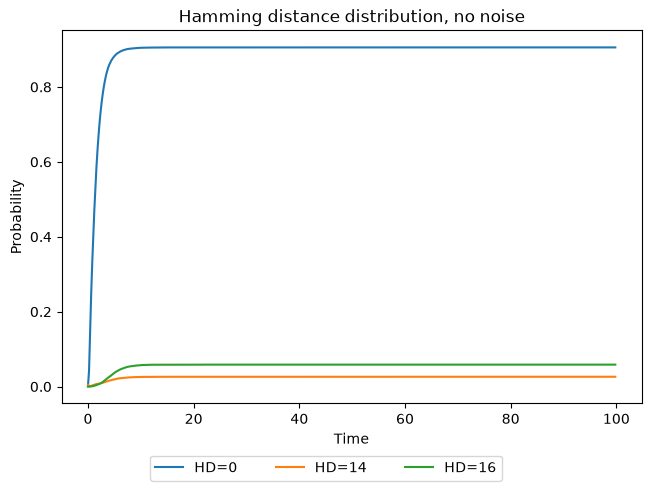

In [4]:
result_no_noise = no_noise.run()

def plot_hamming(result, title):
    hd = pd.read_csv(result.get_probtraj_file(), sep="\t", index_col=0,
                     usecols=lambda c: c == "Time" or c.startswith("HD="))
    hd.loc[:, hd.iloc[-1] >= 0.02].plot(title=title, xlabel="Time", ylabel="Probability")

plot_hamming(result_no_noise, "Hamming distance distribution, no noise")
legend_below()
plt.savefig("figures/droso_hd_no_noise.png")

The asymptotic behavior consists of fixed points:

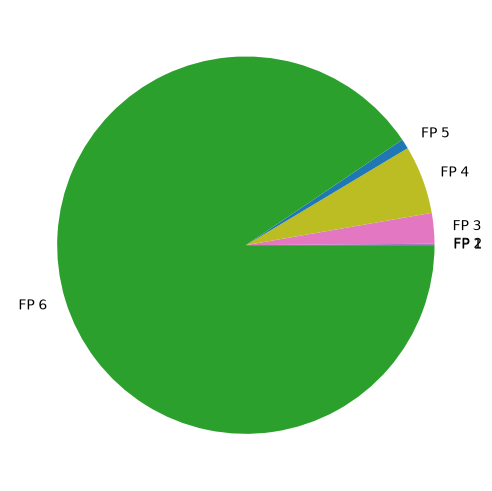

In [5]:
result_no_noise.plot_fixpoint()
plt.savefig("figures/droso_fixed_points.png")

The patterns of the four most probable fixed points: the most probable one is the expected patterning.

In [6]:
fixed_points = result_no_noise.get_fptable().sort_values("Proba", ascending=False)
fixed_points[["State", "Proba"]]

,State,Proba
5,WG4 -- en1 -- EN1 -- hh1 -- HH1 -- CIA2 -- ptc...,0.90562
3,CIR1 -- PTC1 -- ci1 -- CI1 -- CIR2 -- PTC2 -- ...,0.05856
2,WG4 -- en1 -- EN1 -- hh1 -- HH1 -- HH2 -- hh2 ...,0.02616
4,WG4 -- en1 -- EN1 -- hh1 -- HH1 -- PTC1 -- CIA...,0.00844
1,CIA1 -- ptc1 -- PTC1 -- HH2 -- ci1 -- CI1 -- h...,0.00092
0,CIA1 -- ptc1 -- PTC1 -- HH2 -- ci1 -- CI1 -- h...,0.00030


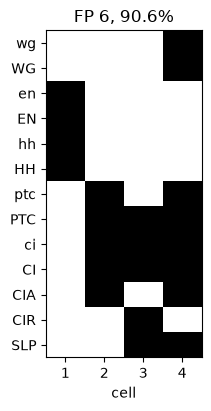

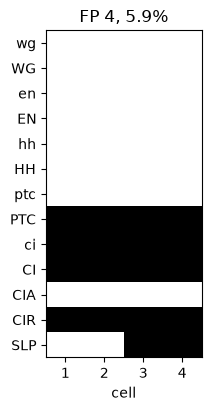

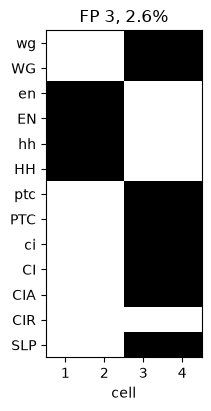

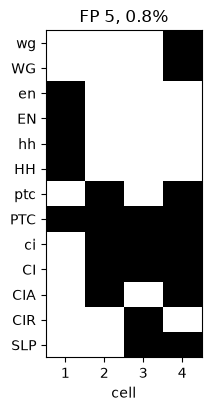

In [7]:
for i, (fp, row) in enumerate(fixed_points.head(4).iterrows()):
    plot_pattern(row["State"].split(" -- ") + ["SLP3", "SLP4"], f"FP {fp + 1}, {row['Proba']:.1%}")
    plt.savefig(f"figures/droso_fp{i + 1}.png")

## With noise

When there is noise (`$noise = 0.01`), the expected patterning is no longer stable. As the simulation visits a
very large number of states, we declare all the nodes as internal: the Hamming distance distribution is still
computed, and the output files stay small.

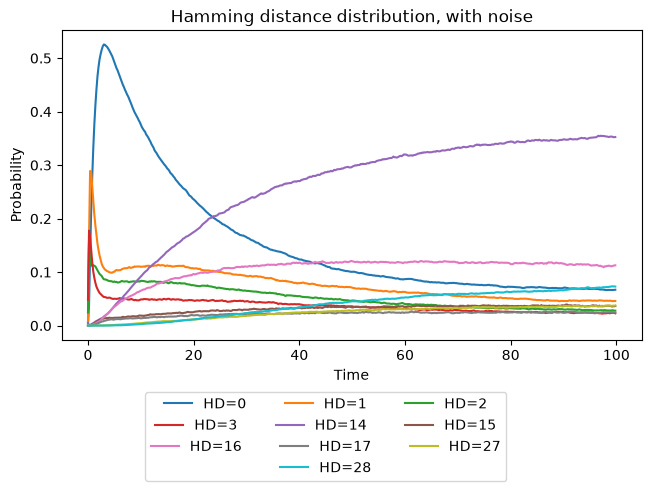

In [8]:
noise = maboss.load("D_Pattern_ContT.bnd", "D_Pattern_ContT_noIntNode_noise.cfg")
for node in noise.network:
    noise.network[node].is_internal = True
result_noise = noise.run()
plot_hamming(result_noise, "Hamming distance distribution, with noise")
legend_below()
plt.savefig("figures/droso_hd_noise.png")

With random noise on the nodes, there is only one indecomposable stationary distribution, in which all the
network states have a non-zero probability. The clustering of stationary distributions would then artificially
separate the estimates: a specific configuration file is used, with a longer maximum time, fewer trajectories,
and a clustering threshold set to 0. The most probable states of the stationary distribution:

In [9]:
stationary = maboss.load("D_Pattern_ContT.bnd", "D_Pattern_ContT_noIntNode_noise_4statdist.cfg")
result_stationary = stationary.run()
distribution = result_stationary.get_statdist_clusters_summary().iloc[0].dropna().sort_values(ascending=False)
distribution.head(4)

WG4 -- en1 -- EN1 -- hh1 -- HH1 -- HH2 -- hh2 -- WG3 -- en2 -- EN2 -- CIA3 -- wg3 -- ptc3 -- PTC3 -- ci3 -- CI3 -- CIA4 -- wg4 -- ptc4 -- PTC4 -- ci4 -- CI4    0.358823
CIA1 -- ptc1 -- PTC1 -- HH2 -- ci1 -- CI1 -- hh2 -- WG3 -- en2 -- EN2 -- CIA3 -- wg3 -- ptc3 -- PTC3 -- ci3 -- CI3 -- CIR4 -- PTC4 -- ci4 -- CI4                0.074930
CIR1 -- PTC1 -- ci1 -- CI1 -- CIR2 -- PTC2 -- ci2 -- CI2 -- CIR3 -- PTC3 -- ci3 -- CI3 -- CIR4 -- PTC4 -- ci4 -- CI4                                            0.066412
WG4 -- en1 -- EN1 -- hh1 -- HH1 -- CIA2 -- ptc2 -- PTC2 -- ci2 -- CI2 -- CIR3 -- PTC3 -- ci3 -- CI3 -- CIA4 -- wg4 -- ptc4 -- PTC4 -- ci4 -- CI4                0.054496
Name: #1, dtype: float64

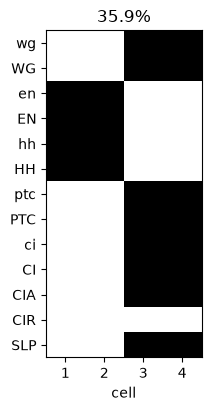

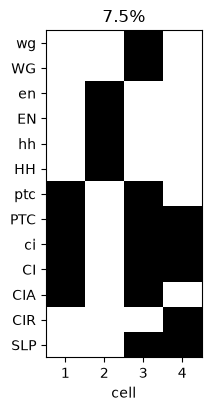

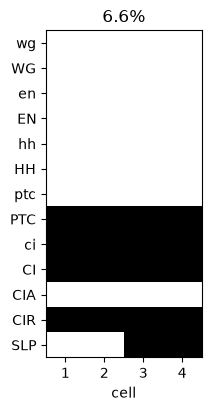

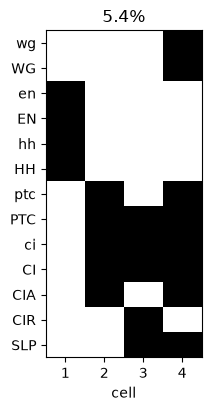

In [10]:
for i, (state, proba) in enumerate(distribution.head(4).items()):
    plot_pattern(state.split(" -- ") + ["SLP3", "SLP4"], f"{proba:.1%}")
    plt.savefig(f"figures/droso_stationary{i + 1}.png")

The most probable state corresponds to a "broad type" patterning, as defined in the publications above:
two adjacent cells have identical node states.